# Live training monitor: 65 TeV

Copy of `inspect-training-live.ipynb` for the separate 65 TeV network (`virgo_65TeV/`). The final cell shows the plots on the independent 65 TeV **test** sample once `job_virgo65_plot.sh` has run.

# Live training monitor

Parses the `train.py` logs of running (or finished) jobs and plots train/val loss and validation AUC per epoch for several runs side by side.

* Edit `RUNS` in the next cell (label -> log file). Logs that don't exist yet show as *not started*.
* Run **Single refresh** for one snapshot, or **Live view** to redraw every `REFRESH_S` seconds until all runs finish (interrupt the kernel to stop early).
* Works with both log formats (`... | AUC: x | Best: y` and the older `... | AUC: x | LR: z | Best: y`).

In [7]:
import os
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, clear_output, display

OUT = "/mnt/scratch/baburish/doublepulse/gnn/Analysis/virgo_65TeV"

# previous RUNS:
# RUNS = {  # label -> log file (at most 3 runs per plot)
#     "Full, 4096 batch waux":       f"{OUT}/full_4096batch_waux.log",
#     "Full, 64 batch":       "/mnt/scratch/baburish/doublepulse/gnn/Analysis/trained_model5TeV/full_gat_cut10_ms1_arch_feats.log",
#     "40k: + brightest/causal":         f"{OUT}/test40k_gat_cut10_arch_feats.log",
#     # "40k: GAT reference":              f"{OUT}/test40k_gat_cut10.log",
# }
RUNS = {  # label -> log file (at most 3 runs per plot)
    "65 TeV: GAT, brightest/causal, aux 1": f"{OUT}/virgo65_gat_arch_feats_aux1.log",
}

# RUNS = {  # label -> log file (at most 3 runs per plot)
#     "40k: + time_unit":                f"{OUT}/test40k_gat_cut10_arch_feats_t33.log",
#     "40k: + time_unit + gelu":         f"{OUT}/test40k_gat_cut10_arch_feats_t33_gelu.log",
#     "40k: + brightest/causal":         f"{OUT}/test40k_gat_cut10_arch_feats.log",
#     "40k: GAT reference":              f"{OUT}/test40k_gat_cut10.log",
# }

# earlier 20k runs (unmatched samples, with PCA):
# RUNS = {"Summaries + edges": f"{OUT}/test20k_edges_baseline.log", "Pulse encoder": f"{OUT}/test20k_domenc.log",
#         "Pulse encoder, no PCA": f"{OUT}/test20k_domenc_nopca.log"}
COMPARISON_DIR = f"{OUT}/evaluation_test"   # test-sample plots (job_virgo65_plot.sh)
PATIENCE = 10    # early-stopping patience of the 65 TeV jobs (job_virgo65.sh default)
REFRESH_S = 10   # live-view refresh interval

In [8]:
# reference palette (light), same as plot_eval.py; runs use slots 1-3
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
RUN_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
})

In [9]:
NUM = r"([-+]?(?:\d+\.?\d*(?:[eE][-+]?\d+)?|nan|inf))"
EPOCH_RE = re.compile(
    rf"Epoch\s+(\d+)\s+\|\s+Train:\s+{NUM}\s+\|\s+Val:\s+{NUM}\s+\|\s+AUC:\s+{NUM}"
    rf"(?:\s+\|\s+LR:\s+{NUM})?\s+\|\s+Best:\s+{NUM}"
)
PBAR_RE = re.compile(r"Train\s+(\d+):\s+\d+%\|[^|]*\|\s*(\d+)/(\d+)")


def parse_log(path):
    """Return (per-epoch DataFrame, status string) for one train.py log."""
    cols = ["epoch", "train_loss", "val_loss", "auc", "lr", "best"]
    if not os.path.exists(path):
        return pd.DataFrame(columns=cols), "not started"

    with open(path, errors="replace") as f:
        text = f.read().replace("\r", "\n")   # tqdm progress bars use \r

    rows = [[int(m.group(1))] + [float(g) if g is not None else np.nan for g in m.groups()[1:]]
            for m in EPOCH_RE.finditer(text)]
    df = pd.DataFrame(rows, columns=cols).drop_duplicates("epoch", keep="last")

    if "Traceback" in text or "Error" in text.split("Epoch")[-1][-2000:]:
        status = "error (see log)"
    elif "Best val AUC" in text:
        m = re.search(r"Early stopping at epoch (\d+)", text)
        status = f"finished (early stop at {m.group(1)})" if m else "finished"
    elif (bars := PBAR_RE.findall(text)):
        ep, done, total = bars[-1]
        status = f"training epoch {int(ep)} ({done}/{total} batches)"
    elif "Collating" in text or "Loading" in text or "No cache" in text:
        status = "building / loading dataset"
    else:
        status = "starting"
    return df, status


def summarize(label, df, status, path):
    row = {"run": label, "status": status, "epochs": len(df)}
    if len(df):
        ib = df["auc"].idxmax()
        row.update({
            "last AUC": round(df["auc"].iloc[-1], 4),
            "best AUC": round(df.loc[ib, "auc"], 4),
            "best epoch": int(df.loc[ib, "epoch"]),
            "epochs since best": int(df["epoch"].iloc[-1] - df.loc[ib, "epoch"]),
            "last val loss": round(df["val_loss"].iloc[-1], 4),
        })
    if os.path.exists(path):
        row["log updated (min ago)"] = round((time.time() - os.path.getmtime(path)) / 60, 1)
    return row

In [10]:
def plot_runs(results):
    """results: list of (label, df, color). Loss on top, validation AUC below."""
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 10.5), sharex=True,
                                        gridspec_kw={"height_ratios": [3, 3, 1.4]})
    for label, df, color in results:
        if df.empty:
            continue
        ax1.plot(df["epoch"], df["train_loss"], color=color, label=f"{label} (train)")
        ax1.plot(df["epoch"], df["val_loss"], color=color, linestyle="--", label=f"{label} (val)")
        vb = df["val_loss"].idxmin()
        ax1.plot(df.loc[vb, "epoch"], df.loc[vb, "val_loss"], "o", color=color, markersize=8,
                 markeredgecolor=SURFACE, markeredgewidth=2)
        ax2.plot(df["epoch"], df["auc"], color=color, label=label)
        if df["lr"].notna().any():
            ax3.step(df["epoch"], df["lr"], where="mid", color=color, linewidth=1.8, label=label)
        ib = df["auc"].idxmax()
        ax2.plot(df.loc[ib, "epoch"], df.loc[ib, "auc"], "o", color=color, markersize=8,
                 markeredgecolor=SURFACE, markeredgewidth=2)
        ax2.annotate(f"{df.loc[ib, 'auc']:.3f}", (df.loc[ib, "epoch"], df.loc[ib, "auc"]),
                     xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9, color=INK_2)
    # epoch-1 loss spike would squash the rest -- scale the loss axis from epoch 2 on
    later = [df.loc[df["epoch"] >= 2, ["train_loss", "val_loss"]].to_numpy()
             for _, df, _ in results if len(df) > 1]
    if later:
        vals = np.concatenate(later).ravel()
        vals = vals[np.isfinite(vals)]
        pad = 0.05 * (vals.max() - vals.min() + 1e-6)
        ax1.set_ylim(vals.min() - pad, vals.max() + pad)
    ax1.set_ylabel("Loss")
    ax1.set_title("Training history (solid = train, dashed = validation; epoch 1 may be off-scale)", loc="left")
    ax2.set_ylabel("Validation AUC")
    ax3.set_xlabel("Epoch")
    ax3.set_ylabel("Learning rate")
    ax3.set_yscale("log")
    ax3.set_title("Learning rate (halved on validation-loss plateau)", loc="left")
    ax2.set_title("Validation AUC (dot = best epoch so far)", loc="left")
    for ax in (ax1, ax2):  # LR panel shares the AUC panel's colours
        if ax.lines:
            ax.legend(loc="best", fontsize=9)
    fig.tight_layout()
    plt.show()


def show():
    results, rows = [], []
    for (label, path), color in zip(RUNS.items(), RUN_COLORS):
        df, status = parse_log(path)
        results.append((label, df, color))
        rows.append(summarize(label, df, status, path))
    summary = pd.DataFrame(rows).set_index("run")
    print(time.strftime("Updated %Y-%m-%d %H:%M:%S"), f"| early-stopping patience = {PATIENCE}")
    display(summary)
    plot_runs(results)
    return summary

## Single refresh

Updated 2026-10-21 12:58:37 | early-stopping patience = 10


,status,epochs
run,,
"65 TeV: GAT, brightest/causal, aux 1",not started,0


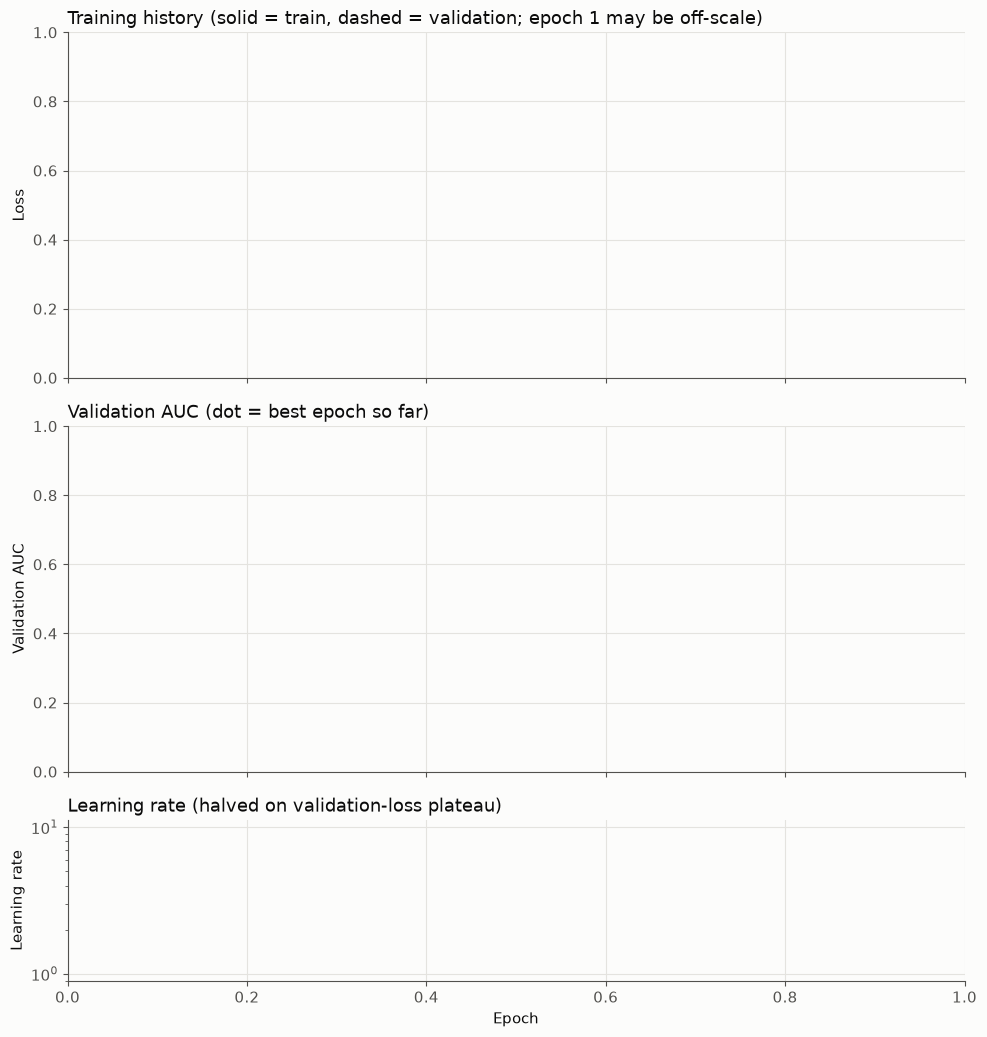

In [11]:
summary = show()

## Live view
Redraws every `REFRESH_S` seconds and stops by itself once every run has finished or errored. Interrupt the kernel (■) to stop earlier.

Updated 2026-10-21 13:23:28 | early-stopping patience = 10


,status,epochs,last AUC,best AUC,best epoch,epochs since best,last val loss,log updated (min ago)
run,,,,,,,,
"65 TeV: GAT, brightest/causal, aux 1",finished (early stop at 11),11,0.5,0.5,1,10,0.6931,0.1


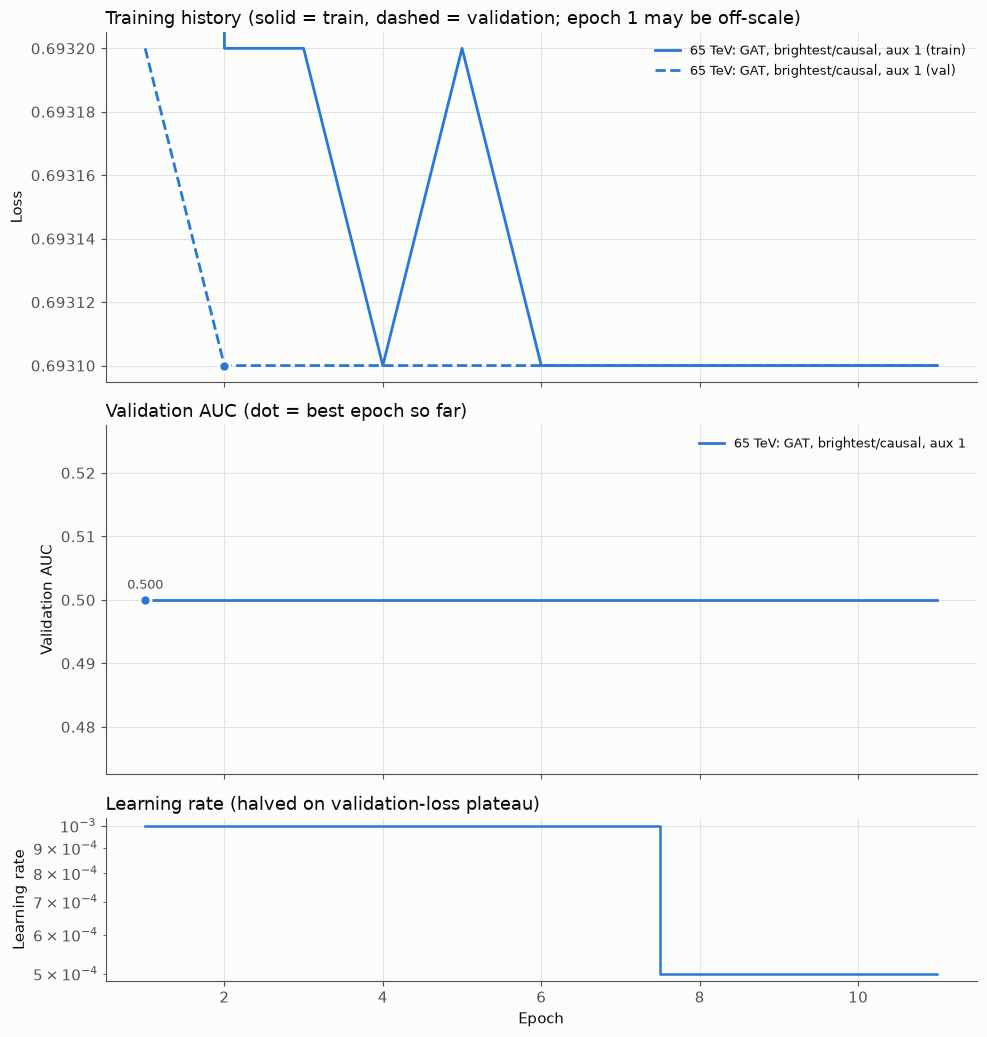

All runs finished.


In [12]:
while True:
    clear_output(wait=True)
    summary = show()
    if summary["status"].str.startswith(("finished", "error")).all():
        print("All runs finished.")
        break
    time.sleep(REFRESH_S)

## Final evaluation plots
Available once the plotting job (`plot_eval.py`) has run after all trainings finish.

In [13]:
for name in ["roc_comparison.png"]:
    p = os.path.join(COMPARISON_DIR, name)
    display(Image(p)) if os.path.exists(p) else print(f"not yet available: {p}")

summary_csv = os.path.join(COMPARISON_DIR, "summary.csv")
if os.path.exists(summary_csv):
    display(pd.read_csv(summary_csv))

for label, path in RUNS.items():
    p = os.path.join(path[:-len(".log")], "test", "score_distribution.png")
    if os.path.exists(p):
        display(Image(p))

not yet available: /mnt/scratch/baburish/doublepulse/gnn/Analysis/virgo_65TeV/evaluation_test/roc_comparison.png
